# Imports e Configurações

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
from banco import conectar

# Configurações de exibição do Pandas
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Configuração visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8


# Funções Utilitárias de Conexão e Formatação

In [12]:
DB_ALVO = 'viagens_transparencia'

def consultar(sql):
    """Executa uma query SELECT e devolve um DataFrame Pandas."""
    conexao = conectar(DB_ALVO)
    if conexao is None:
        print(f"❌ Erro ao conectar à base '{DB_ALVO}'.")
        return None
    try:
        resultado = pd.read_sql(sql, conexao)
        return resultado
    except Exception as e:
        print(f"❌ Erro na consulta SQL: {e}")
        return None
    finally:
        conexao.close()

def executar_ddl(sql_statement):
    """Executa instruções DDL (CREATE, DROP, VIEW) com tratamento transacional."""
    conexao = conectar(DB_ALVO)
    if conexao is None:
        print(f"❌ Erro ao conectar à base '{DB_ALVO}'.")
        return False
    try:
        with conexao.begin():
            conexao.execute(text(sql_statement))
        return True
    except Exception as e:
        print(f"❌ Erro ao executar DDL: {e}")
        return False
    finally:
        conexao.close()

def reais(valor):
    """Formata valor numérico como moeda (R$)."""
    if pd.isna(valor):
        return "R$ 0,00"
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

# Criação da Tabela e da VIEW da Camada Gold
#### (Agregações com JOIN e GROUP BY)

In [14]:
print("=" * 70)
print("CRIANDO CAMADA GOLD: TABELA E VIEW gold_resumo_orgaos")
print("=" * 70 + "\n")

# 1. Criação da Tabela Física Gold
executar_ddl("DROP TABLE IF EXISTS gold_resumo_orgaos;")

sql_cria_tabela_gold = """
CREATE TABLE gold_resumo_orgaos AS
SELECT 
    v.nome_orgao_superior,
    COUNT(DISTINCT v.id_viagem) AS total_viagens,
    COALESCE(ROUND(SUM(v.valor_total), 2), 0) AS custo_total_viagens,
    COALESCE(ROUND(AVG(v.valor_total), 2), 0) AS custo_medio_viagem,
    COALESCE(ROUND(SUM(p.valor), 2), 0) AS total_desembolsado_pagamentos,
    COUNT(p.id_pagamento) AS total_registos_pagamentos
FROM silver_viagens v
LEFT JOIN silver_pagamentos p ON v.id_viagem = p.id_viagem
GROUP BY v.nome_orgao_superior
ORDER BY custo_total_viagens DESC;
"""

if executar_ddl(sql_cria_tabela_gold):
    print("✓ Tabela 'gold_resumo_orgaos' criada com sucesso!")

# 2. Criação da View Analítica Gold
executar_ddl("DROP VIEW IF EXISTS vw_gold_resumo_orgaos;")

sql_cria_view_gold = """
CREATE VIEW vw_gold_resumo_orgaos AS
SELECT 
    v.nome_orgao_superior,
    COUNT(DISTINCT v.id_viagem) AS total_viagens,
    COALESCE(ROUND(SUM(v.valor_total), 2), 0) AS custo_total_viagens,
    COALESCE(ROUND(AVG(v.valor_total), 2), 0) AS custo_medio_viagem,
    COALESCE(ROUND(SUM(p.valor), 2), 0) AS total_desembolsado_pagamentos,
    COUNT(p.id_pagamento) AS total_registos_pagamentos
FROM silver_viagens v
LEFT JOIN silver_pagamentos p ON v.id_viagem = p.id_viagem
GROUP BY v.nome_orgao_superior;
"""

if executar_ddl(sql_cria_view_gold):
    print("✓ View 'vw_gold_resumo_orgaos' criada com sucesso!")

# Visualização prévia da tabela Gold
df_gold_preview = consultar("SELECT * FROM gold_resumo_orgaos LIMIT 5;")
if df_gold_preview is not None:
    print("\nPreview dos primeiros 5 registos da Camada Gold:")
    print(df_gold_preview.to_string(index=False))

CRIANDO CAMADA GOLD: TABELA E VIEW gold_resumo_orgaos

✓ Tabela 'gold_resumo_orgaos' criada com sucesso!
✓ View 'vw_gold_resumo_orgaos' criada com sucesso!

Preview dos primeiros 5 registos da Camada Gold:
                           nome_orgao_superior  total_viagens  custo_total_viagens  custo_medio_viagem  total_desembolsado_pagamentos  total_registos_pagamentos
     Ministério da Justiça e Segurança Pública          75742         7.511634e+09            42698.42                   488831110.61                     175814
                          Ministério da Defesa          61912         3.402822e+08             3616.25                   156549767.91                      93574
                        Ministério da Educação          65295         2.716774e+08             2754.68                   111897434.35                      93340
              Ministério da Previdência Social           8190         1.915703e+08             9397.61                    40659494.63                 

# P1 — Os 5 órgãos com maior custo total 
(com Gráfico 1)

P1: OS 5 ÓRGÃOS COM MAIOR CUSTO TOTAL

                           nome_orgao_superior  total_viagens custo_total_formatado
     Ministério da Justiça e Segurança Pública          75742     R$ 486.933.121,65
                          Ministério da Defesa          61912     R$ 156.070.304,49
                        Ministério da Educação          65295     R$ 111.291.349,34
Ministério do Meio Ambiente e Mudança do Clima          19413      R$ 49.697.710,16
              Ministério da Previdência Social           8190      R$ 40.417.309,06


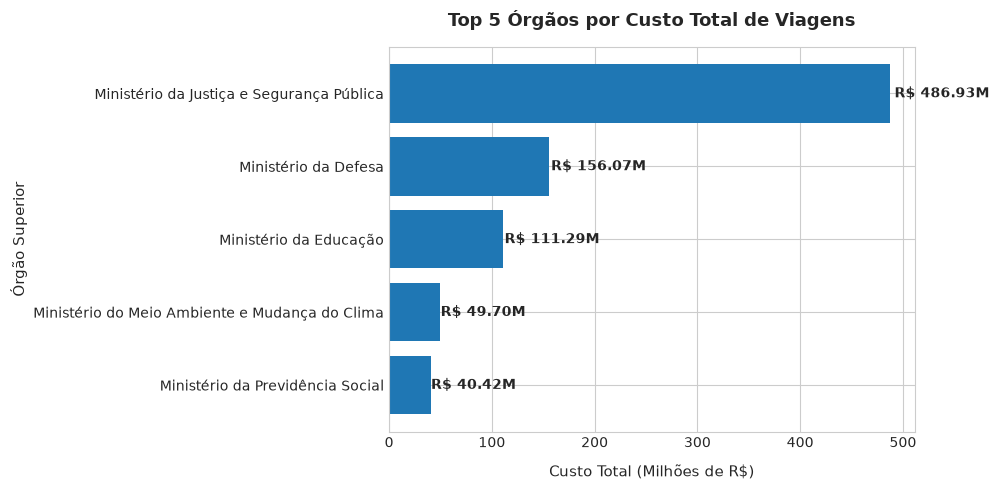

In [15]:
print("=" * 70)
print("P1: OS 5 ÓRGÃOS COM MAIOR CUSTO TOTAL")
print("=" * 70 + "\n")

sql_p1 = """
SELECT 
    nome_orgao_superior,
    ROUND(SUM(valor_total), 2) AS custo_total,
    COUNT(*) AS total_viagens
FROM silver_viagens
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""

df_p1 = consultar(sql_p1)

if df_p1 is not None and not df_p1.empty:
    df_p1['custo_total_formatado'] = df_p1['custo_total'].apply(reais)
    print(df_p1[['nome_orgao_superior', 'total_viagens', 'custo_total_formatado']].to_string(index=False))
    
    # Gráfico 1: Barras horizontais para leitura de nomes longos de órgãos
    plt.figure(figsize=(10, 5))
    barras = plt.barh(df_p1['nome_orgao_superior'][::-1], df_p1['custo_total'][::-1] / 1e6, color='#1f77b4')
    plt.title('Top 5 Órgãos por Custo Total de Viagens', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Custo Total (Milhões de R$)', fontsize=11, labelpad=10)
    plt.ylabel('Órgão Superior', fontsize=11)
    
    for barra in barras:
        largura = barra.get_width()
        plt.text(largura + (largura * 0.01), barra.get_y() + barra.get_height()/2, 
                 f'R$ {largura:.2f}M', ha='left', va='center', fontsize=10, fontweight='bold')
        
    plt.tight_layout()
    plt.show()

# P2 — Os 3 destinos com maior custo médio por viagem


In [16]:
print("=" * 70)
print("P2: OS 3 DESTINOS COM MAIOR CUSTO MÉDIO POR VIAGEM")
print("=" * 70 + "\n")

sql_p2 = """
SELECT 
    destinos,
    ROUND(AVG(valor_total), 2) AS custo_medio,
    ROUND(SUM(valor_total), 2) AS custo_total,
    COUNT(*) AS total_viagens
FROM silver_viagens
WHERE destinos IS NOT NULL AND TRIM(destinos) != ''
GROUP BY destinos
HAVING COUNT(*) >= 3  -- Relevância estatística mínima
ORDER BY custo_medio DESC
LIMIT 3;
"""

df_p2 = consultar(sql_p2)

if df_p2 is not None and not df_p2.empty:
    df_p2['custo_medio_formatado'] = df_p2['custo_medio'].apply(reais)
    df_p2['custo_total_formatado'] = df_p2['custo_total'].apply(reais)
    print(df_p2[['destinos', 'total_viagens', 'custo_medio_formatado', 'custo_total_formatado']].to_string(index=False))

P2: OS 3 DESTINOS COM MAIOR CUSTO MÉDIO POR VIAGEM

                                                                           destinos  total_viagens custo_medio_formatado custo_total_formatado
              Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Brasília/DF, Brasília/DF              3         R$ 125.976,81         R$ 377.930,43
Brasília/DF, Barbacena/MG, Rio de Janeiro/RJ, Brasília/DF, Brasília/DF, Brasília/DF              3         R$ 121.814,17         R$ 365.442,50
                                    Brasília/DF, Belém/PA, Brasília/DF, Brasília/DF              3         R$ 116.741,55         R$ 350.224,64


# P3 — A viagem de maior duração e o seu custo total

In [24]:
print("=" * 70)
print("P3: VIAGEM DE MAIOR DURAÇÃO E VIAGEM DE MAIOR CUSTO TOTAL")
print("=" * 70 + "\n")

# 1. Consulta para a viagem de maior duração
sql_maior_duracao = """
SELECT 
    id_viagem,
    nome_orgao_superior,
    nome_viajante,
    destinos,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagens
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 1;
"""

# 2. Consulta para a viagem de maior custo total
sql_maior_custo = """
SELECT 
    id_viagem,
    nome_orgao_superior,
    nome_viajante,
    destinos,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagens
WHERE valor_total IS NOT NULL
ORDER BY valor_total DESC, duracao_dias DESC
LIMIT 1;
"""

df_duracao = consultar(sql_maior_duracao)
df_custo = consultar(sql_maior_custo)

if df_duracao is not None and not df_duracao.empty:
    v_dur = df_duracao.iloc[0]
    print("🕒 [VIAGEM DE MAIOR DURAÇÃO]")
    print(f"ID da Viagem    : {v_dur['id_viagem']}")
    print(f"Órgão Superior  : {v_dur['nome_orgao_superior']}")
    print(f"Viajante        : {v_dur['nome_viajante']}")
    print(f"Destino(s)      : {v_dur['destinos']}")
    print(f"Período         : {v_dur['data_inicio']} a {v_dur['data_fim']}")
    print(f"Duração         : {v_dur['duracao_dias']} dias")
    print(f"Custo Total     : {reais(v_dur['valor_total'])}")
    print("-" * 70)

if df_custo is not None and not df_custo.empty:
    v_custo = df_custo.iloc[0]
    print("💰 [VIAGEM DE MAIOR CUSTO TOTAL]")
    print(f"ID da Viagem    : {v_custo['id_viagem']}")
    print(f"Órgão Superior  : {v_custo['nome_orgao_superior']}")
    print(f"Viajante        : {v_custo['nome_viajante']}")
    print(f"Destino(s)      : {v_custo['destinos']}")
    print(f"Período         : {v_custo['data_inicio']} a {v_custo['data_fim']}")
    print(f"Duração         : {v_custo['duracao_dias']} dias")
    print(f"Custo Total     : {reais(v_custo['valor_total'])}")
    print("=" * 70 + "\n")

P3: VIAGEM DE MAIOR DURAÇÃO E VIAGEM DE MAIOR CUSTO TOTAL

🕒 [VIAGEM DE MAIOR DURAÇÃO]
ID da Viagem    : 0000000000020699856
Órgão Superior  : Ministério da Previdência Social
Viajante        : LUISANGELA CORREA FRANCO DE FARIA
Destino(s)      : Mogi Mirim/SP
Período         : 2025-01-13 a 2026-01-31
Duração         : 384 dias
Custo Total     : R$ 0,00
----------------------------------------------------------------------
💰 [VIAGEM DE MAIOR CUSTO TOTAL]
ID da Viagem    : 0000000000020914280
Órgão Superior  : Ministério da Defesa
Viajante        : RENATO RODRIGUES DE AGUIAR FREIRE
Destino(s)      : Cingapura/Cingapura
Período         : 2025-05-16 a 2025-06-03
Duração         : 19 dias
Custo Total     : R$ 260.105,52



# P4 — Qual o tipo de pagamento com maior valor médio? 
(com Gráfico 2)


P4: QUAL O TIPO DE PAGAMENTO COM MAIOR VALOR MÉDIO?

           tipo_pagamento  total_registos valor_medio_formatado valor_total_formatado
                  DIÁRIAS          401463           R$ 2.078,28     R$ 834.352.643,52
                 PASSAGEM          188985           R$ 1.878,34     R$ 354.978.915,13
Serviço correlato: seguro            4894             R$ 447,51       R$ 2.190.136,71
              RESTITUIÇÃO           11574             R$ 245,70       R$ 2.843.762,01


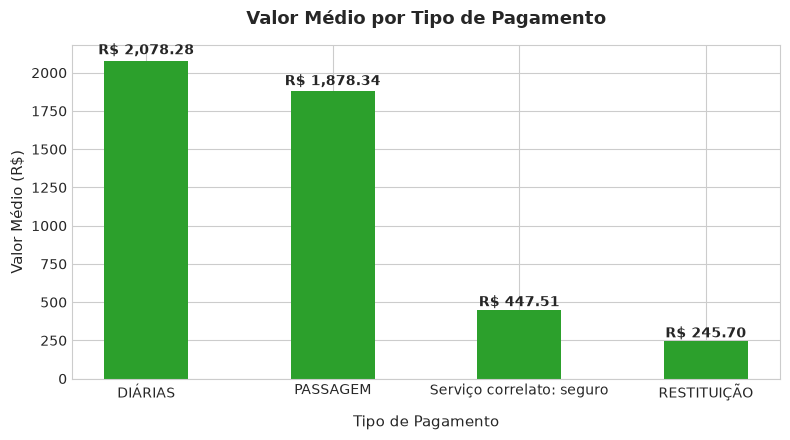

In [18]:
print("=" * 70)
print("P4: QUAL O TIPO DE PAGAMENTO COM MAIOR VALOR MÉDIO?")
print("=" * 70 + "\n")

sql_p4 = """
SELECT 
    tipo_pagamento,
    ROUND(AVG(valor), 2) AS valor_medio,
    ROUND(SUM(valor), 2) AS valor_total,
    COUNT(*) AS total_registos
FROM silver_pagamentos
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC;
"""

df_p4 = consultar(sql_p4)

if df_p4 is not None and not df_p4.empty:
    df_p4['valor_medio_formatado'] = df_p4['valor_medio'].apply(reais)
    df_p4['valor_total_formatado'] = df_p4['valor_total'].apply(reais)
    print(df_p4[['tipo_pagamento', 'total_registos', 'valor_medio_formatado', 'valor_total_formatado']].to_string(index=False))
    
    # Gráfico 2: Barras verticais comparativas
    plt.figure(figsize=(8, 4.5))
    barras = plt.bar(df_p4['tipo_pagamento'], df_p4['valor_medio'], color='#2ca02c', width=0.45)
    plt.title('Valor Médio por Tipo de Pagamento', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Tipo de Pagamento', fontsize=11, labelpad=10)
    plt.ylabel('Valor Médio (R$)', fontsize=11)
    
    for barra in barras:
        altura = barra.get_height()
        plt.text(barra.get_x() + barra.get_width()/2, altura + (altura * 0.01),
                 f'R$ {altura:,.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
                 
    plt.tight_layout()
    plt.show()

# P5 — Qual o meio de transporte mais usado nos trechos? 
(com Gráfico 3)

P5: QUAL O MEIO DE TRANSPORTE MAIS USADO NOS TRECHOS?

meio_transporte  total_trechos
Veículo Oficial         386424
          Aéreo         232666
     Rodoviário          64970
Veículo Próprio          42846
       Inválido          26659
        Fluvial           8429
    Ferroviário            874
       Marítimo            481


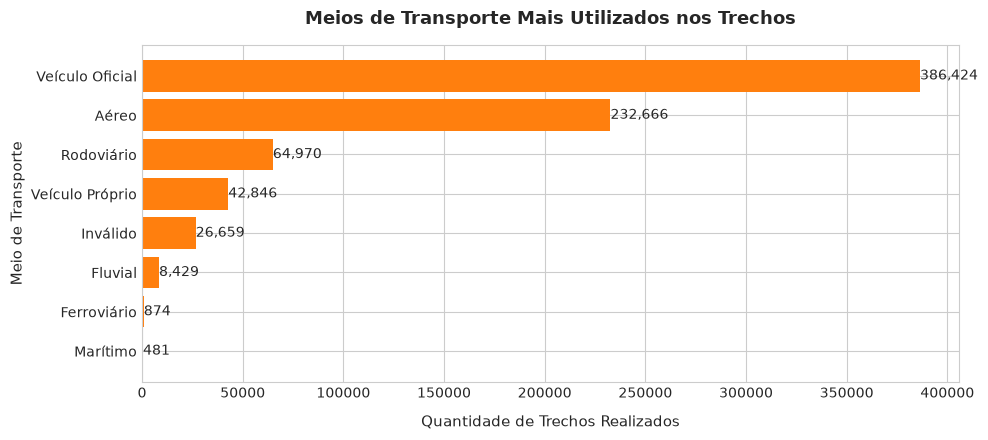

In [19]:
print("=" * 70)
print("P5: QUAL O MEIO DE TRANSPORTE MAIS USADO NOS TRECHOS?")
print("=" * 70 + "\n")

sql_p5 = """
SELECT 
    meio_transporte,
    COUNT(*) AS total_trechos
FROM silver_trechos
WHERE meio_transporte IS NOT NULL AND TRIM(meio_transporte) != ''
GROUP BY meio_transporte
ORDER BY total_trechos DESC;
"""

df_p5 = consultar(sql_p5)

if df_p5 is not None and not df_p5.empty:
    print(df_p5.to_string(index=False))
    
    # Gráfico 3: Distribuição por meio de transporte
    plt.figure(figsize=(10, 4.5))
    barras = plt.barh(df_p5['meio_transporte'][::-1], df_p5['total_trechos'][::-1], color='#ff7f0e')
    plt.title('Meios de Transporte Mais Utilizados nos Trechos', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Quantidade de Trechos Realizados', fontsize=11, labelpad=10)
    plt.ylabel('Meio de Transporte', fontsize=11)
    
    for barra in barras:
        largura = barra.get_width()
        plt.text(largura + 2, barra.get_y() + barra.get_height()/2, 
                 f'{int(largura):,}', ha='left', va='center', fontsize=10)
                 
    plt.tight_layout()
    plt.show()

# P6 — Qual UF de destino aparece em mais trechos?


In [20]:
print("=" * 70)
print("P6: QUAL UF DE DESTINO APARECE EM MAIS TRECHOS?")
print("=" * 70 + "\n")

sql_p6 = """
SELECT 
    destino_uf,
    COUNT(*) AS total_trechos
FROM silver_trechos
WHERE destino_uf IS NOT NULL AND TRIM(destino_uf) != ''
GROUP BY destino_uf
ORDER BY total_trechos DESC
LIMIT 10;
"""

df_p6 = consultar(sql_p6)

if df_p6 is not None and not df_p6.empty:
    print(df_p6.to_string(index=False))
    top_uf = df_p6.iloc[0]
    print(f"\n🏆 Destino com maior fluxo: {top_uf['destino_uf']} com {top_uf['total_trechos']} trechos registados.")

P6: QUAL UF DE DESTINO APARECE EM MAIS TRECHOS?

        destino_uf  total_trechos
         São Paulo          82722
  Distrito Federal          79962
      Minas Gerais          50965
    Rio de Janeiro          44197
            Paraná          42603
              Pará          40044
 Rio Grande do Sul          38684
Mato Grosso do Sul          30516
             Bahia          28375
        Pernambuco          28372

🏆 Destino com maior fluxo: São Paulo com 82722 trechos registados.


# P7 — Qual órgão pagou mais no total?

In [21]:
print("=" * 70)
print("P7: QUAL ÓRGÃO PAGOU MAIS NO TOTAL?")
print("=" * 70 + "\n")

sql_p7 = """
SELECT 
    nome_orgao_pagador,
    ROUND(SUM(valor), 2) AS total_pago,
    COUNT(*) AS total_pagamentos
FROM silver_pagamentos
WHERE nome_orgao_pagador IS NOT NULL AND TRIM(nome_orgao_pagador) != ''
GROUP BY nome_orgao_pagador
ORDER BY total_pago DESC
LIMIT 5;
"""

df_p7 = consultar(sql_p7)

if df_p7 is not None and not df_p7.empty:
    df_p7['total_pago_formatado'] = df_p7['total_pago'].apply(reais)
    print(df_p7[['nome_orgao_pagador', 'total_pagamentos', 'total_pago_formatado']].to_string(index=False))
    top_pagador = df_p7.iloc[0]
    print(f"\n🏆 Órgão com maior desembolso: {top_pagador['nome_orgao_pagador']} "
          f"com {top_pagador['total_pago_formatado']}.")

P7: QUAL ÓRGÃO PAGOU MAIS NO TOTAL?

                 nome_orgao_pagador  total_pagamentos total_pago_formatado
Fundo Nacional de Segurança Pública             79816    R$ 278.481.047,89
                           Sigiloso             93141    R$ 200.484.801,68
             Comando da Aeronáutica             46193     R$ 81.769.144,77
Instituto Nacional do Seguro Social             18324     R$ 37.427.601,45
                Comando do Exército             22837     R$ 36.872.643,95

🏆 Órgão com maior desembolso: Fundo Nacional de Segurança Pública com R$ 278.481.047,89.


# Auditoria Final das Camadas Raw, Silver e Gold

In [22]:
print("=" * 70)
print("AUDITORIA DE VOLUMETRIA (RAW vs SILVER vs GOLD)")
print("=" * 70 + "\n")

sql_auditoria = """
SELECT 'raw_viagens' AS tabela, COUNT(*) AS linhas FROM raw_viagens
UNION ALL
SELECT 'raw_pagamentos', COUNT(*) FROM raw_pagamentos
UNION ALL
SELECT 'raw_passagens', COUNT(*) FROM raw_passagens
UNION ALL
SELECT 'raw_trechos', COUNT(*) FROM raw_trechos
UNION ALL
SELECT 'silver_viagens', COUNT(*) FROM silver_viagens
UNION ALL
SELECT 'silver_pagamentos', COUNT(*) FROM silver_pagamentos
UNION ALL
SELECT 'silver_passagens', COUNT(*) FROM silver_passagens
UNION ALL
SELECT 'silver_trechos', COUNT(*) FROM silver_trechos
UNION ALL
SELECT 'gold_resumo_orgaos', COUNT(*) FROM gold_resumo_orgaos;
"""

df_auditoria = consultar(sql_auditoria)
if df_auditoria is not None:
    print(df_auditoria.to_string(index=False))

AUDITORIA DE VOLUMETRIA (RAW vs SILVER vs GOLD)

            tabela  linhas
gold_resumo_orgaos      35
  silver_passagens  167260
     raw_passagens  167260
 silver_pagamentos  606916
    silver_viagens  341860
       raw_viagens  341860
    silver_trechos  763349
       raw_trechos  763349
    raw_pagamentos  606916
